# 01 · Data preparation and baselines

Downloads the LinkedIn Job Postings dataset from Kaggle, cleans it, maps the six original experience levels to four (Entry, Mid, Senior, Executive), segments each description into sections, and makes the stratified 70/15/15 split. Then runs the two non-neural baselines: rule-based regex and TF-IDF + logistic regression.

The split files saved here are read by the later notebooks. Final numbers: see the paper.

# **SETUP**

In [ ]:
!pip install scikit-learn pandas numpy matplotlib seaborn
!pip install transformers datasets accelerate torch
!pip install kagglehub

In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Download latest version
path = kagglehub.dataset_download("arshkon/linkedin-job-postings")

print("Path to dataset files:", path)


print("\nFiles in dataset:")
for f in os.listdir(path):
    print(f)

csv_path = os.path.join(path, "postings.csv")

df = pd.read_csv(csv_path)
print("\nDataFrame head:")
df.head()


100%|██████████| 159M/159M [00:08<00:00, 19.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/arshkon/linkedin-job-postings/versions/13

Files in dataset:
companies
mappings
jobs
postings.csv

DataFrame head:


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


#**Data Cleaning**

In [ ]:
# Keep useful columns
keep_cols = ['title', 'description', 'skills_desc', 'formatted_experience_level']
df = df[keep_cols]

print("Remaining columns:", df.columns)
print("Rows:", len(df))
df.head()

Remaining columns: Index(['title', 'description', 'skills_desc', 'formatted_experience_level'], dtype='object')
Rows: 123849


,title,description,skills_desc,formatted_experience_level
0,Marketing Coordinator,Job descriptionA leading real estate firm in N...,Requirements: \n\nWe are seeking a College or ...,NaN
1,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",NaN,NaN
2,Assitant Restaurant Manager,The National Exemplar is accepting application...,We are currently accepting resumes for FOH - A...,NaN
3,Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,This position requires a baseline understandin...,NaN
4,Service Technician,Looking for HVAC service tech with experience ...,NaN,NaN


In [ ]:

df = df.dropna(subset=['description']) # Drop rows with missing description
df = df[df['description'].str.len() > 30] # Remove very short descriptions
df = df.drop_duplicates(subset=['description']) # Remove duplicate job descriptions
df['skills_desc'] = df['skills_desc'].fillna('') # Replace NAN in skill description
df = df.dropna(subset=['formatted_experience_level'])  # Drop NAN in formatted experience level

print(df.shape)
df.head()
df.to_csv('cleaned_job_data.csv', index=False)
print(f"Saved {len(df)} data to cleaned_job_data.csv")

(80717, 4)
Saved 80717 data to cleaned_job_data.csv


#**Experience Level Labeling & Dataset Segmentation**

In [ ]:
import pandas as pd
import re
import os
from sklearn.model_selection import train_test_split

df = pd.read_csv('cleaned_job_data.csv')

cols_to_drop = ['section_responsibilities', 'section_requirements', 'section_other', 'full_text']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

experience_mapping = {
    'Entry level': 'Entry',
    'Internship': 'Entry',
    'Associate': 'Mid',
    'Mid-Senior level': 'Senior',
    'Director': 'Executive',
    'Executive': 'Executive'
}

df['experience_level'] = df['formatted_experience_level'].map(experience_mapping)
df = df.dropna(subset=['experience_level'])

print("=" * 80)
print(f"Total samples: {len(df)}")
print(df['experience_level'].value_counts())

# Section Extraction Functions
def find_responsibilities_flexible(raw_text, verbose=False):
    resp_pattern = re.compile(
        r'(?im)(?:^|[\n\r])[ \t]*(?:'
        r'responsibilities?[\s:‚Äì\-–—]*|'
        r'job\s+duties?[\s:‚Äì\-–—]*|'
        r'duties[\s:‚Äì\-–—]+|'
        r'essential\s+functions?[\s:‚Äì\-–—]*|'
        r'key\s+responsibilities?[\s:‚Äì\-–—]*|'
        r'primary\s+responsibilities?[\s:‚Äì\-–—]*|'
        r'your\s+responsibilities?[\s:‚Äì\-–—]*|'
        r'what\s+you.*ll\s+do[\s:‚Äì\-–—]*|'
        r'in\s+this\s+role[\s:‚Äì\-–—]*|'
        r'role\s+description[\s:‚Äì\-–—]*|'
        r'position\s+overview[\s:‚Äì\-–—]*'
        r')'
    )

    match = resp_pattern.search(raw_text)

    if match:
        start = match.end()
        stop_pattern = re.compile(
            r'(?im)(?:^|[\n\r])[ \t]*(?:'
            r'requirements?|qualifications?|skills?|education|experience|'
            r'benefits?|compensation|salary|about\s+(?:us|the)|'
            r'physical\s+requirements?|work\s+environment|'
            r'how\s+to\s+apply|equal\s+opportunity'
            r')[\s:‚Äì\-–—]*'
        )
        stop_match = stop_pattern.search(raw_text, start)
        end = stop_match.start() if stop_match else len(raw_text)
        return raw_text[start:end].strip(), start, end

    # Fallback: extract bullet points
    bullet_pattern = r'(?:^[ \t]*[‚Ä¢\-\*•]\s*[^\n]+(?:\n|$)){3,}'
    bullet_match = re.search(bullet_pattern, raw_text, re.MULTILINE)

    if bullet_match:
        start = bullet_match.start()
        lines = raw_text[start:].split('\n')
        end_line = 0
        non_bullet_count = 0

        for i, line in enumerate(lines):
            stripped = line.strip()
            is_bullet = bool(re.match(r'^[ \t]*[‚Ä¢\-\*•]', line))
            is_header = bool(re.match(
                r'^[ \t]*(?:requirements?|qualifications?|skills?|education|benefits?)',
                stripped, re.IGNORECASE
            ))

            if is_header:
                end_line = i
                break

            if not is_bullet and len(stripped) > 0:
                non_bullet_count += 1
                if non_bullet_count >= 2:
                    end_line = i
                    break
            else:
                non_bullet_count = 0

        if end_line == 0:
            end_line = len(lines)

        section_text = '\n'.join(lines[:end_line]).strip()
        end = start + len('\n'.join(lines[:end_line]))
        return section_text, start, end

    # Fallback: first 1/3 of text
    third = len(raw_text) // 3
    return raw_text[:third], 0, third

def find_requirements_flexible(raw_text, verbose=False):
    req_pattern = re.compile(
        r'(?im)(?:^|[\n\r])[ \t]*(?:'
        r'requirements?|'
        r'qualifications?|'
        r'minimum\s+qualifications?|'
        r'required\s+qualifications?|'
        r'skills?\s*(?:and|&)?\s*qualifications?|'
        r'education\s*(?:and|&)?\s*experience|'
        r'what\s+you.*ll\s+need|'
        r'what\s+we.*re\s+looking\s+for|'
        r'ideal\s+candidate|'
        r'about\s+you'
        r')[\s:‚Äì\-–—]*'
    )

    match = req_pattern.search(raw_text)

    if match:
        start = match.end()
        stop_pattern = re.compile(
            r'(?im)(?:^|[\n\r])[ \t]*(?:'
            r'responsibilities?|duties|benefits?|compensation|'
            r'about\s+us|physical\s+requirements?|work\s+environment|'
            r'how\s+to\s+apply|equal\s+opportunity'
            r')[\s:‚Äì\-–—]*'
        )
        stop_match = stop_pattern.search(raw_text, start)
        end = stop_match.start() if stop_match else len(raw_text)
        return raw_text[start:end].strip(), start, end

    return '', None, None

def normalize_segment(text):
    if not text:
        return ''
    text = re.sub(r'‚Äô|‚Äì|‚Äú|‚Äù', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

def segment_job_posting_final(row):
    description = str(row['description']) if pd.notna(row['description']) else ''
    skills = str(row['skills_desc']) if pd.notna(row['skills_desc']) else ''

    raw_text = description + '\n' + skills
    raw_text = re.sub(r'‚Äô|‚Äì|‚Äú|‚Äù', '', raw_text)

    # Responsibilities
    responsibilities, resp_start, resp_end = find_responsibilities_flexible(raw_text)

    # Requirements
    requirements, req_start, req_end = find_requirements_flexible(raw_text)

    # Fallback: skills_desc
    if not requirements and skills and len(skills) > 50:
        requirements = skills
        req_start, req_end = None, None

    # Fallback: middle 1/3
    if not requirements or len(requirements) < 50:
        start = len(raw_text) // 3
        end = 2 * len(raw_text) // 3
        requirements = raw_text[start:end]
        req_start, req_end = start, end

    # Other
    spans = []
    if resp_start is not None and resp_end is not None:
        spans.append((resp_start, resp_end))
    if req_start is not None and req_end is not None:
        spans.append((req_start, req_end))

    spans = sorted(spans, key=lambda x: x[0])

    other_chunks = []
    cursor = 0

    for start, end in spans:
        if cursor < start:
            other_chunks.append(raw_text[cursor:start])
        cursor = max(cursor, end)

    if cursor < len(raw_text):
        other_chunks.append(raw_text[cursor:])

    other = '\n'.join(other_chunks).strip()

    if not other:
        other = description

    # Normalize all segments
    responsibilities_norm = normalize_segment(responsibilities)
    requirements_norm = normalize_segment(requirements)
    other_norm = normalize_segment(other)

    # Remove overlapping content in sections
    def remove_overlap(text1, text2):
        if len(text1) < 50 or len(text2) < 50:
            return text1, text2

        words1 = set(text1.lower().split())
        words2 = set(text2.lower().split())

        if not words1 or not words2:
            return text1, text2

        overlap = len(words1 & words2) / max(len(words1), len(words2))

        if overlap > 0.5:
            if len(text1) > len(text2):
                return text1, 'N/A'
            else:
                return 'N/A', text2

        return text1, text2

    responsibilities_norm, requirements_norm = remove_overlap(
        responsibilities_norm, requirements_norm
    )

    # validate and clean
    def clean_and_validate(text, min_len=20, max_len=2000):
        if not text or len(text) < min_len:
            return 'N/A'
        text = text.strip()
        if len(text) > max_len:
            text = text[:max_len] + '...'
        return text

    return {
        'section_responsibilities': clean_and_validate(responsibilities_norm),
        'section_requirements': clean_and_validate(requirements_norm),
        'section_other': clean_and_validate(other_norm, min_len=0)
    }

print("\nStart processing all data...")

from tqdm import tqdm
tqdm.pandas()

sections_df = df.progress_apply(segment_job_posting_final, axis=1, result_type='expand')
df = pd.concat([df, sections_df], axis=1)

total = len(df)
resp_non_na = int((df['section_responsibilities'] != 'N/A').sum())
req_non_na = int((df['section_requirements'] != 'N/A').sum())
other_non_na = int((df['section_other'] != 'N/A').sum())

print(f"\nExtraction results:")
print(f"  Responsibilities: {resp_non_na}/{total} ({resp_non_na/total*100:.1f}%)")
print(f"  Requirements: {req_non_na}/{total} ({req_non_na/total*100:.1f}%)")
print(f"  Other: {other_non_na}/{total} ({other_non_na/total*100:.1f}%)")

# ========= Use this for TF-IDF ============
# The segmented sections are used by BERT, which encodes each part separately

df['full_text'] = df['description'].fillna('').astype(str) + ' ' + df['skills_desc'].fillna('').astype(str)

# Save complete dataset
df.to_csv('segmented_job_data_final.csv', index=False)
print(f"\nSaved: segmented_job_data_final.csv")

# Split data

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['experience_level'],
    random_state=42
)

dev_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['experience_level'],
    random_state=42
)

print(f"Train: {len(train_df)} ({len(train_df)/total*100:.1f}%)")
print(f"Dev: {len(dev_df)} ({len(dev_df)/total*100:.1f}%)")
print(f"Test: {len(test_df)} ({len(test_df)/total*100:.1f}%)")

# Save splits
train_df.to_csv('train_data_final.csv', index=False)
dev_df.to_csv('dev_data_final.csv', index=False)
test_df.to_csv('test_data_final.csv', index=False)


Total samples: 80717
experience_level
Senior       36110
Entry        31453
Mid           8719
Executive     4435
Name: count, dtype: int64

Start processing all data...


100%|██████████| 80717/80717 [00:55<00:00, 1465.59it/s]



Extraction results:
  Responsibilities: 79023/80717 (97.9%)
  Requirements: 73495/80717 (91.1%)
  Other: 80717/80717 (100.0%)

Saved: segmented_job_data_final.csv
Train: 56501 (70.0%)
Dev: 12108 (15.0%)
Test: 12108 (15.0%)


# **Rule-Based Baseline (Regex)**

REGEX BASELINE RESULTS (Optimized)
Accuracy:  0.5035
Macro F1:  0.4284

Classification Report:
              precision    recall  f1-score   support

       Entry     0.7903    0.1039    0.1836      4718
   Executive     0.7655    0.7402    0.7527       666
         Mid     0.1651    0.1093    0.1316      1308
      Senior     0.4981    0.9177    0.6457      5416

    accuracy                         0.5035     12108
   macro avg     0.5548    0.4678    0.4284     12108
weighted avg     0.5907    0.5035    0.4160     12108



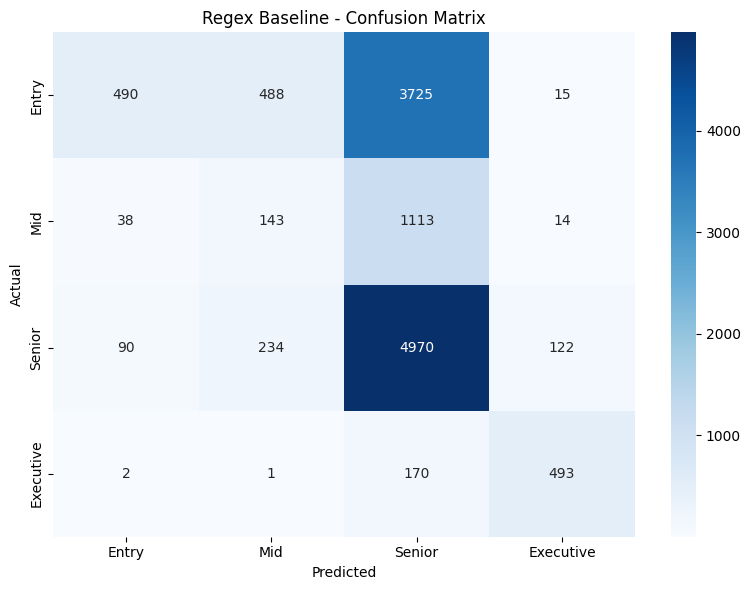


Sample Misclassifications:

True: Entry | Pred: Executive
Title: Assistant Director of Development Research

True: Entry | Pred: Executive
Title: Director, Carrier & Connectivity Partnerships

True: Entry | Pred: Mid
Title: Restoration Associate, Keweenaw Forests

True: Entry | Pred: Mid
Title: Social Worker LPC, LCSW or LMFT

True: Entry | Pred: Senior
Title: Data Engineer

True: Entry | Pred: Senior
Title: Income Tax Preparer

True: Executive | Pred: Entry
Title: Parking Control Attendant

True: Executive | Pred: Entry
Title: Baltimore, MD - Clinical Research Coordinator

True: Executive | Pred: Mid
Title: Registered Nurse

True: Executive | Pred: Senior
Title: Plant Controller


/tmp/ipython-input-2767367014.py:155: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_errors = errors.groupby(['experience_level', 'pred_regex']).apply(


In [ ]:
import re
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# load data
train_df = pd.read_csv('train_data_final.csv')
dev_df = pd.read_csv('dev_data_final.csv')
test_df = pd.read_csv('test_data_final.csv')

# Regex Baseline

def regex_classify(row):
    title = str(row.get('title', '')).lower()
    desc = str(row.get('description', '')).lower()
    text = title + ' ' + desc

    # Executive
    exec_title_patterns = [
        r'\bdirector\b',
        r'\bvice[- ]?president\b',
        r'\b\bvp\b',
        r'\bchief\b',
        r'\bceo\b', r'\bcto\b', r'\bcfo\b', r'\bcoo\b', r'\bcmo\b',
        r'\bgeneral manager\b',
        r'\bmanaging director\b',
        r'\bhead of\b',
        r'\bpresident\b',
        r'\bevp\b', r'\bsvp\b',
    ]
    for p in exec_title_patterns:
        if re.search(p, title):
            return 'Executive'

    # Entry
    entry_title_patterns = [
        r'\bentry[- ]?level\b',
        r'\bjunior\b',
        r'\bintern\b(?!al)',
        r'\binternship\b',
        r'\btrainee\b',
        r'\bapprentice\b',
    ]
    for p in entry_title_patterns:
        if re.search(p, title):
            return 'Entry'

    # Mid
    if re.search(r'\bassociate\b', title) and not re.search(r'\bsenior\s+associate\b', title):
        return 'Mid'

    # Senior
    senior_title_patterns = [
        r'\bsenior\b',
        r'\bsr\.\b',
        r'\bsr\s',
        r'\blead\b',
        r'\bprincipal\b',
        r'\bstaff\b',
        r'\barchitect\b',
    ]
    for p in senior_title_patterns:
        if re.search(p, title):
            return 'Senior'

    # Executive indicators in description
    exec_desc_patterns = [
        r'\breport(?:s|ing)?\s+(?:to|directly to)\s+(?:the\s+)?(?:ceo|cto|cfo|board|c-suite)\b',
        r'\blead(?:s|ing)?\s+(?:a\s+)?team\s+of\s+\d{2,}',  # leads team of 10+
        r'\b(?:p&l|profit.{0,5}loss)\s+responsibility\b',
    ]
    for p in exec_desc_patterns:
        if re.search(p, desc):
            return 'Executive'

    # Entry indicators in description
    entry_desc_patterns = [
        r'\bno\s+experience\s+(?:required|necessary|needed)\b',
        r'\b0[- ]?(?:to[- ]?)?[12]\s+years?\b',
        r'\brecent\s+grad(?:uate)?\b',
        r'\bnew\s+grad(?:uate)?\b',
        r'\bentry[- ]?level\b',
        r'\bwill\s+train\b',
        r'\btraining\s+provided\b',
    ]
    for p in entry_desc_patterns:
        if re.search(p, desc):
            return 'Entry'

    # Senior indicators in description
    senior_desc_patterns = [
        r'\b[5-9]\+?\s*years?\s+(?:of\s+)?experience\b',
        r'\b\d{2}\+?\s*years?\s+(?:of\s+)?experience\b',  # 10+ years
        r'\bextensive\s+experience\b',
        r'\bproven\s+track\s+record\b',
    ]
    for p in senior_desc_patterns:
        if re.search(p, desc):
            return 'Senior'

    # Mid indicators in description
    mid_desc_patterns = [
        r'\b[23][- ]?(?:to[- ]?)?[45]?\s*years?\s+(?:of\s+)?experience\b',
        r'\bsome\s+experience\b',
    ]
    for p in mid_desc_patterns:
        if re.search(p, desc):
            return 'Mid'

    # default return the most frequent type
    return 'Senior'

# evaluate on test set

test_df['pred_regex'] = test_df.apply(regex_classify, axis=1)

y_true = test_df['experience_level']
y_pred = test_df['pred_regex']

# metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average='macro')

print("=" * 60)
print("REGEX BASELINE RESULTS (Optimized)")
print("=" * 60)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro F1:  {macro_f1:.4f}")
print("\n" + "=" * 60)
print("Classification Report:")
print("=" * 60)
print(classification_report(y_true, y_pred, digits=4))

# Confusion Matrix
labels = ['Entry', 'Mid', 'Senior', 'Executive']
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Regex Baseline - Confusion Matrix')
plt.tight_layout()
plt.savefig('regex_confusion_matrix.png', dpi=150)
plt.show()

# sample misclassifications
print("\n" + "=" * 60)
print("Sample Misclassifications:")
print("=" * 60)

errors = test_df[test_df['experience_level'] != test_df['pred_regex']]
sample_errors = errors.groupby(['experience_level', 'pred_regex']).apply(
    lambda x: x.sample(min(2, len(x)), random_state=42)
).reset_index(drop=True)

for _, row in sample_errors.head(10).iterrows():
    print(f"\nTrue: {row['experience_level']} | Pred: {row['pred_regex']}")
    print(f"Title: {row['title']}")

# **TF—IDF (LR)**

Train: 56501, Dev: 12108, Test: 12108
TF-IDF features: 5000

Hyperparameter Tuning on Dev Set
C= 0.01 -> Dev Acc: 0.6423, Macro F1: 0.3501
C=  0.1 -> Dev Acc: 0.6981, Macro F1: 0.5235
C=    1 -> Dev Acc: 0.7259, Macro F1: 0.6263
C=   10 -> Dev Acc: 0.7170, Macro F1: 0.6370
C=  100 -> Dev Acc: 0.7042, Macro F1: 0.6228

Best C: 1 (Dev Acc: 0.7259)

Final Evaluation on Test Set

Accuracy:  0.7345
Macro F1:  0.6349

Classification Report:
              precision    recall  f1-score   support

       Entry     0.7577    0.8008    0.7786      4718
   Executive     0.7941    0.5210    0.6292       666
         Mid     0.6164    0.2592    0.3649      1308
      Senior     0.7219    0.8178    0.7669      5416

    accuracy                         0.7345     12108
   macro avg     0.7225    0.5997    0.6349     12108
weighted avg     0.7284    0.7345    0.7205     12108



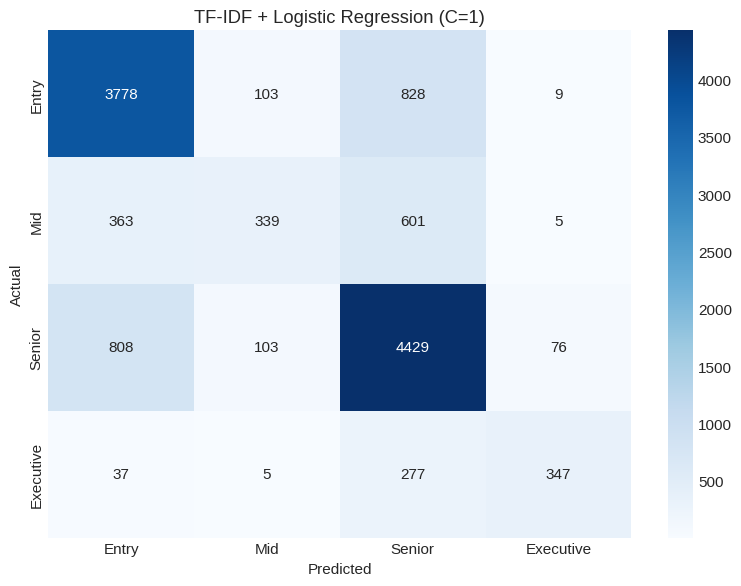


Top Features per Class:

Entry: intern, entry level, coordinator, internship, technician, lpn, clerk, associate, specialist, assistant

Executive: director, general manager, leadership, vp, chief, 10 years, controller, vice, vice president, oversee

Mid: volunteer, aon, associate, specialist, company description, countries, connectivity, applicable law, coordinator, additional information

Senior: manager, senior, sr, supervisor, rn, lead, technologist, service representative, consultant, registered nurse


In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns

# load data
train_df = pd.read_csv('train_data_final.csv')
dev_df = pd.read_csv('dev_data_final.csv')
test_df = pd.read_csv('test_data_final.csv')

# title + description
train_df['text'] = train_df['title'].fillna('') + ' ' + train_df['description'].fillna('')
dev_df['text'] = dev_df['title'].fillna('') + ' ' + dev_df['description'].fillna('')
test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

X_train, y_train = train_df['text'], train_df['experience_level']
X_dev, y_dev = dev_df['text'], dev_df['experience_level']
X_test, y_test = test_df['text'], test_df['experience_level']

print(f"Train: {len(X_train)}, Dev: {len(X_dev)}, Test: {len(X_test)}")

# TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),  # unigrams + bigrams
    min_df=5,
    max_df=0.8,
    stop_words='english'
)

# fit on train，and then transform all data
X_train_tfidf = tfidf.fit_transform(X_train)
X_dev_tfidf = tfidf.transform(X_dev)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF features: {X_train_tfidf.shape[1]}")

# hyperparameter tuning on dev
print("\n" + "=" * 60)
print("Hyperparameter Tuning on Dev Set")
print("=" * 60)

# Grid search for best C (regularization strength)
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

best_acc = 0
best_C = 1

for C in param_grid['C']:
    clf = LogisticRegression(C=C, max_iter=1000, random_state=42, n_jobs=-1)
    clf.fit(X_train_tfidf, y_train)
    dev_pred = clf.predict(X_dev_tfidf)
    acc = accuracy_score(y_dev, dev_pred)
    f1 = f1_score(y_dev, dev_pred, average='macro')
    print(f"C={C:5} -> Dev Acc: {acc:.4f}, Macro F1: {f1:.4f}")

    if acc > best_acc:
        best_acc = acc
        best_C = C

print(f"\nBest C: {best_C} (Dev Acc: {best_acc:.4f})")

# retrain with best parameter + evaluate on test
print("\n" + "=" * 60)
print("Final Evaluation on Test Set")
print("=" * 60)

clf_final = LogisticRegression(C=best_C, max_iter=1000, random_state=42, n_jobs=-1)
clf_final.fit(X_train_tfidf, y_train)

y_pred = clf_final.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"\nAccuracy:  {accuracy:.4f}")
print(f"Macro F1:  {macro_f1:.4f}")
print("\n" + "=" * 60)
print("Classification Report:")
print("=" * 60)
print(classification_report(y_test, y_pred, digits=4))

# Confusion Matrix
labels = ['Entry', 'Mid', 'Senior', 'Executive']
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'TF-IDF + Logistic Regression (C={best_C})')
plt.tight_layout()
plt.savefig('tfidf_confusion_matrix.png', dpi=150)
plt.show()

# feature importance
print("\n" + "=" * 60)
print("Top Features per Class:")
print("=" * 60)

feature_names = tfidf.get_feature_names_out()
for i, label in enumerate(clf_final.classes_):
    top_indices = clf_final.coef_[i].argsort()[-10:][::-1]
    top_features = [feature_names[j] for j in top_indices]
    print(f"\n{label}: {', '.join(top_features)}")